In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("housing.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
print("Dataset Information:")
print("--------------------")

df.info()

print("\nMissing Values:")
print("--------------------")

print(df.isnull().sum())

print("\nStatistical Summary:")
print("--------------------")

df.describe()

Dataset Information:
--------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
--------------------
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households     

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


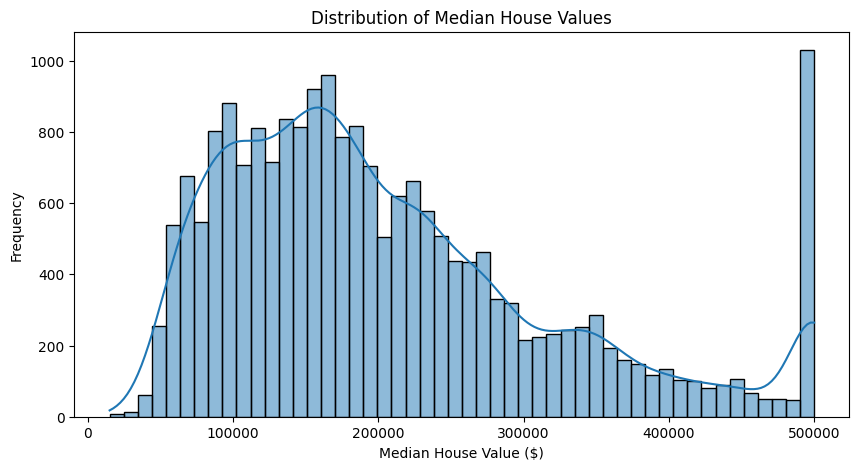

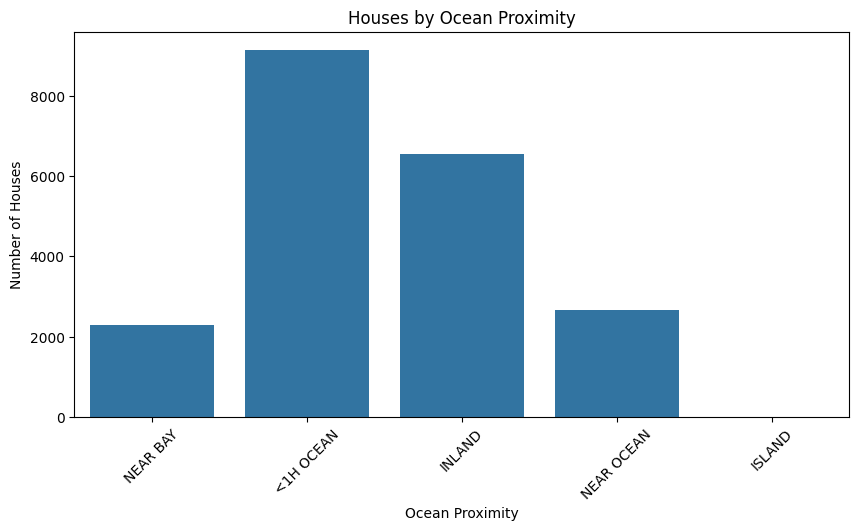

In [3]:
plt.figure(figsize=(10, 5))
sns.histplot(df["median_house_value"], bins=50, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="ocean_proximity")
plt.title("Houses by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Houses")
plt.xticks(rotation=45)
plt.show()

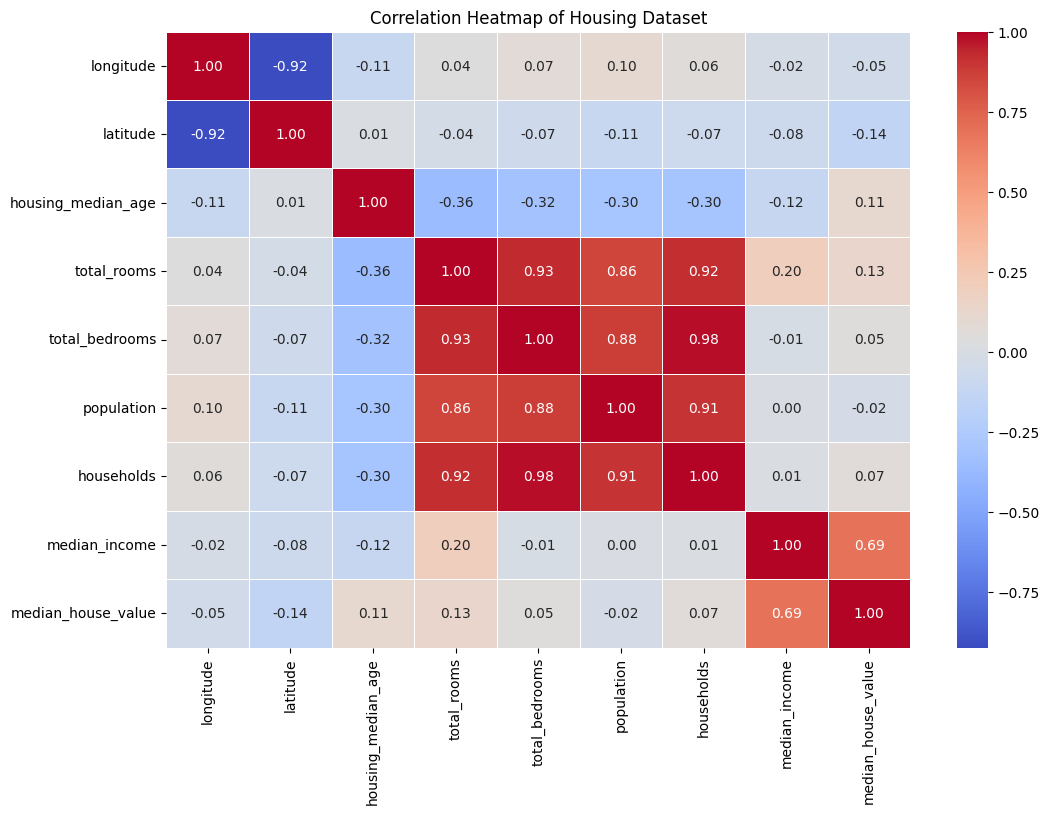

Correlation with Median House Value:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


In [4]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Housing Dataset")
plt.show()

print("Correlation with Median House Value:")
print(correlation["median_house_value"].sort_values(ascending=False))

In [5]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]

df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]

df["population_per_household"] = df["population"] / df["households"]

df["income_age_interaction"] = df["median_income"] * df["housing_median_age"]

print("New Features Created Successfully!")

print("\nUpdated Dataset Shape:")
print(df.shape)

print("\nNew Features:")
print(df[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
    "income_age_interaction"
]].head())

New Features Created Successfully!

Updated Dataset Shape:
(20640, 14)

New Features:
   rooms_per_household  bedrooms_per_room  population_per_household  \
0             6.984127           0.146591                  2.555556   
1             6.238137           0.155797                  2.109842   
2             8.288136           0.129516                  2.802260   
3             5.817352           0.184458                  2.547945   
4             6.281853           0.172096                  2.181467   

   income_age_interaction  
0                341.3332  
1                174.3294  
2                377.3848  
3                293.4412  
4                200.0024  


In [6]:
from sklearn.model_selection import train_test_split

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Data Splitting Completed Successfully!")

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Data Splitting Completed Successfully!

Training Data Shape: (16512, 13)
Testing Data Shape: (4128, 13)

Training Target Shape: (16512,)
Testing Target Shape: (4128,)


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")
print("\nNumerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))
print("\nNumerical Columns:", numeric_features)
print("Categorical Columns:", categorical_features)

Preprocessing Pipeline Created Successfully!

Numerical Features: 12
Categorical Features: 1

Numerical Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_age_interaction']
Categorical Columns: ['ocean_proximity']


In [8]:
from sklearn.linear_model import LinearRegression

ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("OLS Linear Regression Model Trained Successfully!")

ols_predictions = ols_model.predict(X_test)

print("\nFirst 10 Predicted House Values:")
print(ols_predictions[:10])

OLS Linear Regression Model Trained Successfully!

First 10 Predicted House Values:
[ 37218.26384014 139754.90357    295755.21092525 280255.75113142
 264184.72967773 184663.37034283 275508.40921487 206458.80554528
 259016.81402999 426689.57846515]


In [9]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

ridge_parameters = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_parameters,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

best_ridge_model = ridge_grid.best_estimator_

ridge_predictions = best_ridge_model.predict(X_test)

print("Ridge Regression Training Completed!")
print("\nBest Alpha:", ridge_grid.best_params_["model__alpha"])
print("Best Cross-Validation RMSE:", -ridge_grid.best_score_)

Ridge Regression Training Completed!

Best Alpha: 1
Best Cross-Validation RMSE: 67720.72484368541


In [10]:
from sklearn.linear_model import Lasso

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])

lasso_parameters = {
    "model__alpha": [0.1, 1, 10, 100]
}

lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_parameters,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_grid.fit(X_train, y_train)

best_lasso_model = lasso_grid.best_estimator_

lasso_predictions = best_lasso_model.predict(X_test)

print("Lasso Regression Training Completed!")
print("\nBest Alpha:", lasso_grid.best_params_["model__alpha"])
print("Best Cross-Validation RMSE:", -lasso_grid.best_score_)

Lasso Regression Training Completed!

Best Alpha: 1
Best Cross-Validation RMSE: 67721.65288914008


In [11]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

results = []

for model_name, predictions in models.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print(results_df.round(2))

MODEL PERFORMANCE COMPARISON
   Model      RMSE       MAE  R2 Score
0    OLS  69048.19  49376.49      0.64
1  Ridge  69056.22  49382.63      0.64
2  Lasso  69049.25  49377.34      0.64


Best Performing Model: OLS
Mean Residual: 687.14


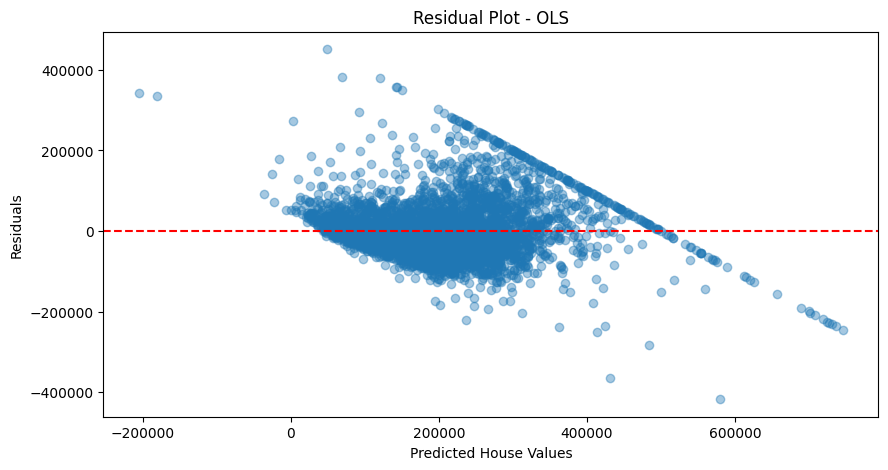

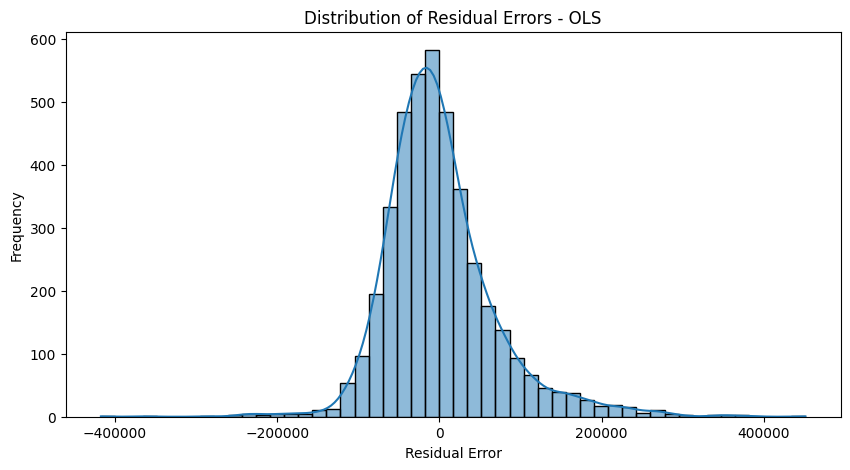

In [12]:
best_model_name = results_df.loc[results_df["RMSE"].idxmin(), "Model"]

predictions_dict = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

best_predictions = predictions_dict[best_model_name]

residuals = y_test - best_predictions

print("Best Performing Model:", best_model_name)
print("Mean Residual:", round(residuals.mean(), 2))

plt.figure(figsize=(10, 5))
plt.scatter(best_predictions, residuals, alpha=0.4)
plt.axhline(y=0, color="red", linestyle="--")
plt.title(f"Residual Plot - {best_model_name}")
plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(residuals, bins=50, kde=True)
plt.title(f"Distribution of Residual Errors - {best_model_name}")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.show()

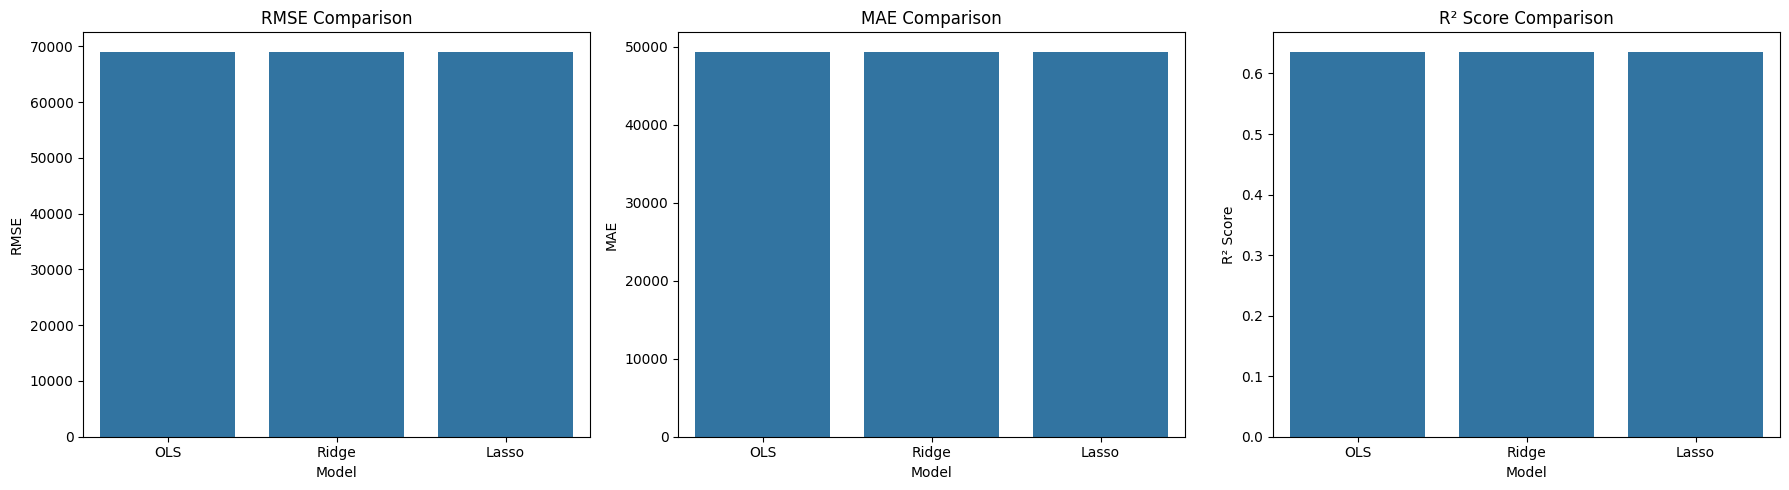

Model Performance Visualization Completed!


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[0])
axes[0].set_title("RMSE Comparison")
axes[0].set_ylabel("RMSE")

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[1])
axes[1].set_title("MAE Comparison")
axes[1].set_ylabel("MAE")

sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² Score Comparison")
axes[2].set_ylabel("R² Score")

plt.tight_layout()
plt.show()

print("Model Performance Visualization Completed!")

In [14]:
best_result = results_df.loc[results_df["RMSE"].idxmin()]

print("FINAL PROJECT RESULTS")
print("---------------------")

print("Best Model:", best_result["Model"])
print("RMSE:", round(best_result["RMSE"], 2))
print("MAE:", round(best_result["MAE"], 2))
print("R2 Score:", round(best_result["R2 Score"], 4))

print("\nPROJECT CONCLUSION")
print("------------------")

print(
    f"The {best_result['Model']} model achieved the lowest test RMSE "
    f"among the three models. Ridge and Lasso regularization were used "
    f"to reduce the effects of multicollinearity. Feature engineering, "
    f"missing-value imputation, categorical encoding and feature scaling "
    f"were applied to prepare the dataset."
)

results_df.to_csv("model_comparison_results.csv", index=False)

print("\nModel comparison results saved successfully!")

FINAL PROJECT RESULTS
---------------------
Best Model: OLS
RMSE: 69048.19
MAE: 49376.49
R2 Score: 0.6362

PROJECT CONCLUSION
------------------
The OLS model achieved the lowest test RMSE among the three models. Ridge and Lasso regularization were used to reduce the effects of multicollinearity. Feature engineering, missing-value imputation, categorical encoding and feature scaling were applied to prepare the dataset.

Model comparison results saved successfully!


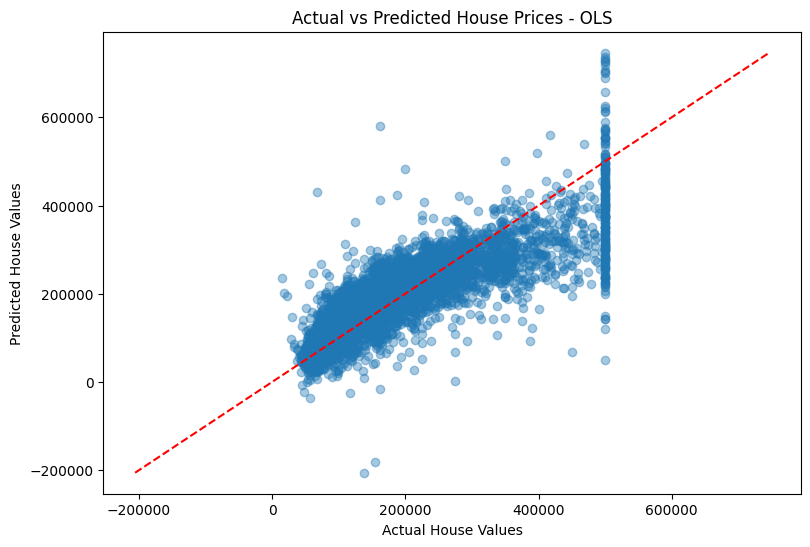

Actual vs Predicted Comparison Completed!


In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, best_predictions, alpha=0.4)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--"
)

plt.title(f"Actual vs Predicted House Prices - {best_model_name}")
plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.show()

print("Actual vs Predicted Comparison Completed!")

In [16]:
import joblib

trained_models = {
    "OLS": ols_model,
    "Ridge": best_ridge_model,
    "Lasso": best_lasso_model
}

best_model = trained_models[best_model_name]

joblib.dump(best_model, "best_housing_price_model.pkl")

print("Best Model Saved Successfully!")
print("Selected Model:", best_model_name)
print("File Name: best_housing_price_model.pkl")

Best Model Saved Successfully!
Selected Model: OLS
File Name: best_housing_price_model.pkl
